# 2 · Finding factions: clustering beyond k-means

**The question:** inside each party, are there distinct groups? We compare five methods, each choosing
its own number of groups by its standard rule (none is told the answer):

| Method | Idea | Picks the number of groups by |
|---|---|---|
| k-means | round clusters around centres | silhouette score |
| Gaussian mixture | elliptical clusters, *soft* membership ("70% this group") | BIC (fit vs complexity) |
| HDBSCAN | dense regions; members between them are "noise" | automatic |
| Ward (hierarchical) | merge closest groups step by step | silhouette score |
| Network communities | link each member to their 15 most-agreeing colleagues, find communities | automatic (Louvain) |

All except the network method cluster the 2-D logistic-PCA positions from notebook 1.

In [1]:
%matplotlib inline
import os, json, warnings
os.chdir('..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ideology import plot
plot.style()
pd.set_option('display.width', 160)

from ideology import cluster, embed

## 1 · Answer key: the synthetic Congress

Six factions: in each party a wing, a mainstream and moderates that differ by *degree* along left-right,
plus a Republican hard-line faction that differs in *kind* (the second dimension).
*ARI* compares a clustering with the true factions (0 = chance, 1 = identical).

In [2]:
pd.read_csv('results/synthetic_clusters.csv').round(2)

,method,k,ari,nmi,party_ari
0,kmeans,3,0.58,0.70,0.78
1,gmm,3,0.58,0.73,0.82
2,hdbscan,2,0.13,0.34,0.04
3,ward,3,0.58,0.71,0.80
4,network,5,0.66,0.74,0.47
5,kmeans (told k=6),6,0.42,0.62,0.33


- k-means, the mixture and Ward each find **3 groups: Democrats, Republicans, and the hard-liners**.
  Factions that differ only by degree blend into a continuum: **there is no gap to find**, and forcing
  k-means to make 6 groups (told the right answer) scores *worse*, because it cuts the continuum at
  arbitrary points.
- HDBSCAN chains the two parties together through their moderates.
- Network communities come closest to the six factions.

## 2 · The real House: the 119th Congress (2025-)

To check clusters against something the votes never saw, we use **caucus membership** from Wikipedia's
current member lists: the Freedom Caucus (which doesn't publish its roster; Wikipedia lists publicly
identified members), the Progressive Caucus, the Blue Dog Coalition and the bipartisan Problem Solvers.

In [3]:
mem = pd.read_csv('results/members_119H.csv')
rep = json.load(open('results/caucus_match_119H.json'))
{k: f"{v['matched']} of {v['listed']} matched (list retrieved {v['retrieved']})" for k, v in rep.items()}

{'Freedom Caucus': '31 of 31 matched (list retrieved 2026-10-17)',
 'Progressive Caucus': '98 of 100 matched (list retrieved 2026-10-17)',
 'Blue Dog Coalition': '10 of 10 matched (list retrieved 2026-10-17)',
 'Problem Solvers Caucus': '48 of 49 matched (list retrieved 2026-10-17)'}

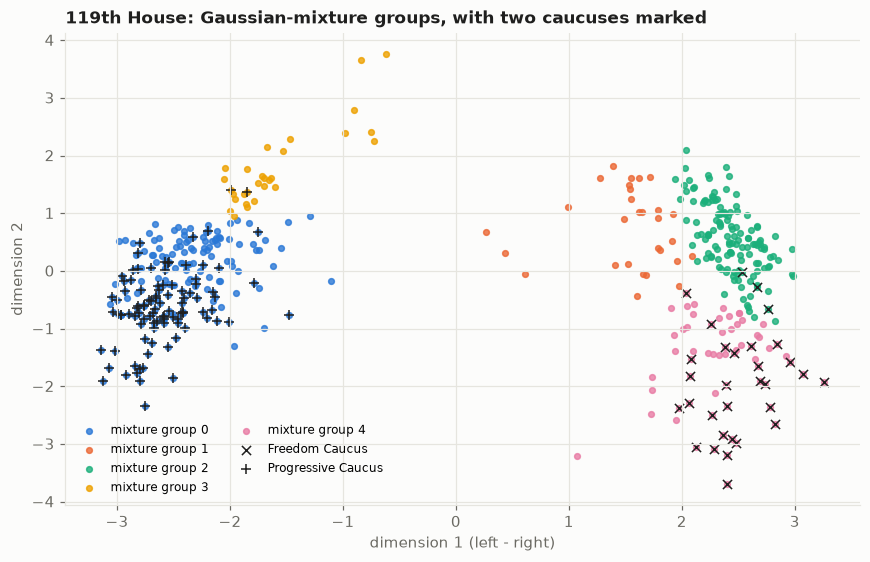

In [4]:
fig, ax = plt.subplots(figsize=(8, 5.2))
lab = mem.gmm
for k, g in mem.groupby('gmm'):
    ax.scatter(g.dim1, g.dim2, s=14, color=plot.SERIES[k], label=f'mixture group {k}', alpha=0.8)
for name, marker in (('Freedom Caucus', 'x'), ('Progressive Caucus', '+')):
    g = mem[mem.caucus.str.contains(name)]
    ax.scatter(g.dim1, g.dim2, s=36, marker=marker, color=plot.INK, linewidths=1, label=name)
ax.set_xlabel('dimension 1 (left - right)'); ax.set_ylabel('dimension 2')
ax.set_title('119th House: Gaussian-mixture groups, with two caucuses marked')
ax.legend(fontsize=8, ncol=2, loc='lower left')
plt.tight_layout()

**How well each method captures each caucus** (best-matching cluster's F1 within the caucus's party:
1.0 = a cluster containing exactly that caucus), **and how stable it is**: we resample the roll calls
20 times, redo everything and compare with the original clustering (median ARI; 1.0 = always the same).

In [5]:
pd.read_csv('results/clusters_119H.csv').round(2)

,method,k,party_ari,Freedom Caucus (R),Problem Solvers Caucus (R),Progressive Caucus (D),Blue Dog Coalition (D),Problem Solvers Caucus (D),stability_median_ari,stability_p10_ari
0,kmeans,3,0.71,0.55,0.24,0.63,0.63,0.34,0.95,0.92
1,gmm,5,0.61,0.59,0.52,0.66,0.31,0.44,0.75,0.57
2,hdbscan,2,0.96,0.24,0.18,0.62,0.05,0.19,0.97,0.95
3,ward,3,0.84,0.70,0.21,0.61,0.09,0.21,0.87,0.77
4,network,5,0.42,0.61,0.37,0.82,0.15,0.33,0.68,0.55


**The trade-off:** the methods that find the most faction structure are the least stable.

- **HDBSCAN** and **k-means** are very stable, but mostly return the two parties.
- **Ward** captures the Freedom Caucus best (F1 0.70).
- **Network communities** isolate most of the Progressive Caucus (F1 0.82), but change most between
  resamples.
- The **Gaussian mixture** is the most even across caucuses, and its *soft* membership says which
  members sit between groups:

In [6]:
bic = pd.read_csv('results/gmm_bic_119H.csv')
print('mixture groups chosen by BIC:', int(bic.loc[bic.bic.idxmin(), 'k']))
unsure = mem[mem.gmm_max_membership < 0.8]
print(f'{len(unsure)} members have no group above 80% membership; by party:', unsure.party.value_counts().to_dict())

mixture groups chosen by BIC: 5
86 members have no group above 80% membership; by party: {'Democrat': 45, 'Republican': 41}


## What this shows

- **Groups that differ in kind** (voting against their own leadership) show up as clusters; groups that
  differ only by degree form a continuum, and any line through it is a choice, not a discovery.
- No single best method: report clusters **with** their stability, and prefer soft membership when
  members sit between groups.
- Party-level clustering is the trivial result. Caucus membership, which the votes never saw, is
  the meaningful check.